# 06 · La simulación: thin-file a distancia controlada

En Home Credit no vimos ventaja de la SNGP, y nuestra explicación es que los thin-file no están lejos del resto. Para probar esa explicación necesitamos datos donde nosotros controlemos la distancia, o sea datos simulados donde conocemos la verdad. Si la explicación es correcta, la ventaja de la SNGP tiene que aparecer cuando los thin-file están lejos y desaparecer cuando están cerca.

- **Lee:** nada externo (los datos se generan acá). Usa `redes.py` y `conformal.py`.
- **Guarda:** `outputs/sim_resultados.csv`, `outputs/sim_resumen.csv`, `outputs/F4_simulacion.pdf/.png` y `outputs/F5_fdr_thin_sim.pdf/.png`.
- **En el informe:** sección 4.3. La Figura 5 es `F4_simulacion` y la Figura 6 es `F5_fdr_thin_sim`. De acá salen los +19 / +18 puntos a distancia 6, el rango de la ventaja hasta distancia 2, el ρ = 0,86 / 0,28 del panel (a, que ahora dibuja la mediana por tramo de distancia sobre la nube de puntos) y el 12,7% / 11,8% de la versión agrupada. El Bloque 6 muestra el mecanismo detrás de la Figura 5: cómo ordena cada modelo a los thin-file que caen en la trampa.
- **Tiempo:** es lo más pesado del proyecto (5 escenarios x 10 semillas x 7 redes), alrededor de una hora en CPU.

In [1]:
# Bloque 1. La función que simula: 20 mil clientes con historial y 4 mil thin-file, con 10 variables normales. A cada
# thin-file lo corremos una distancia al azar (entre 0 y dist_max) en la variable 0 (la que en el informe llamamos x1).
# El riesgo verdadero tiene una "trampa" lejos de los datos: cerca, más x0 quiere decir MENOS riesgo, pero cuando x0
# pasa de 2.5 se activa un término que SUBE la morosidad. Un modelo que solo vio clientes cerca (como XGBoost, que
# extiende hacia afuera lo último que vio) va a creer que un thin-file muy lejano es muy seguro, y se equivoca. Un
# modelo que sabe que "ahí no tiene datos" (la SNGP) vuelve hacia el promedio y no se confía.
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
from xgboost import XGBClassifier

from redes import SNGP, entrenar, ajustar_covarianza, predecir   # las piezas de la red, en redes.py
from conformal import conformal_select                          # Conformal Selection (p-valores + BH)



def simular(seed, n_hist=20_000, n_thin=4_000, d=10, dist_max=6.0, fuerza=2.0):
    """Datos sintéticos. Devuelve X, y (1 = moroso), thin (True/False) y la distancia de cada uno.
    n_hist / n_thin: cantidad de clientes con historial / sin historial.
    d: cantidad de variables. dist_max: qué tan lejos pueden estar los thin-file.
    fuerza: cuánto sube la morosidad lejos de los datos (la "trampa")."""
    rng = np.random.default_rng(seed)                   # generador con semilla: mismos datos cada vez
    X_h = rng.normal(size=(n_hist, d))                  # clientes con historial: normales estándar
    X_t = rng.normal(size=(n_thin, d))                  # thin-file: igual, pero...
    dist = rng.uniform(0, dist_max, size=n_thin)        # ...cada uno con una distancia al azar
    X_t[:, 0] += dist                                   # corrida en la variable 0
    X = np.vstack([X_h, X_t]).astype(np.float32)        # todos juntos (float32 para torch)
    thin = np.r_[np.zeros(n_hist, bool), np.ones(n_thin, bool)]   # np.r_ pega vectores: False x n_hist, True x n_thin
    # Riesgo verdadero: lineal cerca de los datos + trampa que se activa con x0 > 2.5
    # -2.2 fija una morosidad base baja (~10%); x0 alto = menos riesgo y x1 alto = más riesgo; np.maximum(0, x0 - 2.5)
    # vale 0 hasta x0 = 2.5 y después crece: ahí arranca la trampa
    z = -2.2 - 0.8 * X[:, 0] + 0.5 * X[:, 1] + fuerza * np.maximum(0, X[:, 0] - 2.5)
    y = rng.binomial(1, 1 / (1 + np.exp(-z)))           # sorteamos quién es moroso (1 con prob. sigmoide(z))
    return X, y.astype(np.float32), thin, np.r_[np.zeros(n_hist), dist]

In [2]:
# Bloque 2. Una corrida completa para una semilla: simular, partir, entrenar XGBoost, la SNGP y el ensamble, y
# devolver las predicciones sobre el pool. La partición imita a Home Credit pero exagera lo que nos interesa: train
# lleva el 60% de los clientes con historial y apenas el 2% de los thin-file (los modelos casi no los ven al
# entrenar). Lo que queda se reparte entre validación (para el early stopping) y el pool (donde corre el conformal).
# La SNGP y el ensamble son exactamente los mismos que en Home Credit (mismas redes, mismas semillas 1000 + k).
K = 5                                              # redes del ensamble (igual que en Home Credit)
def correr_semilla(seed, dist_max=6.0, frac_thin_train=0.02):
    """Devuelve un DataFrame del pool con thin, y, dist y los scores de cada modelo.
    seed: semilla (cambia los datos y los modelos). dist_max: qué tan lejos pueden estar los thin-file.
    frac_thin_train: qué fracción de los thin-file entra a train (2%: casi ninguno)."""
    X, y, thin, dist = simular(seed, dist_max=dist_max)
    rng = np.random.default_rng(seed)
    idx_h = rng.permutation(np.where(~thin)[0])        # índices con historial, mezclados
    idx_t = rng.permutation(np.where(thin)[0])         # índices thin-file, mezclados
    nh, nt = len(idx_h), len(idx_t)                    # cuántos hay de cada tipo
    n_tr_t = int(frac_thin_train * nt)                 # cuántos thin-file van a train
    # Cortamos cada lista mezclada en pedazos: el primer 60% de los con historial (y el 2% de thin-file) a train,
    # el siguiente 10% de cada uno a validación, y el resto al pool
    i_tr = np.r_[idx_h[:int(0.6 * nh)], idx_t[:n_tr_t]]                                   # train
    i_va = np.r_[idx_h[int(0.6 * nh):int(0.7 * nh)], idx_t[n_tr_t:n_tr_t + int(0.1 * nt)]]  # validación
    i_po = np.r_[idx_h[int(0.7 * nh):], idx_t[n_tr_t + int(0.1 * nt):]]                   # pool

    # XGBoost: hasta 1000 árboles, frena si la validación no mejora en 50 seguidos.
    # learning_rate: cuánto corrige cada árbol nuevo; max_depth: profundidad máxima de cada árbol;
    # eval_metric="logloss": la pérdida que mira en validación; n_jobs=-1: todos los núcleos
    xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4,
                        early_stopping_rounds=50, eval_metric="logloss",
                        random_state=seed, n_jobs=-1)
    xgb.fit(X[i_tr], y[i_tr], eval_set=[(X[i_va], y[i_va])], verbose=False)   # eval_set: contra qué datos frena
    mu_xgb = xgb.predict_proba(X[i_po])[:, 0]          # columna 0 = prob. de buen pago

    # SNGP: la misma red de Home Credit (128 de ancho, 2 bloques), ahora con 10 variables
    torch.manual_seed(seed)                            # pesos iniciales y mezcla reproducibles
    ds_tr = TensorDataset(torch.from_numpy(X[i_tr]), torch.from_numpy(y[i_tr]))   # pares (x, y) de train como tensores
    tr = DataLoader(ds_tr, batch_size=512, shuffle=True)   # tandas de 512, mezcladas en cada época
    va = DataLoader(TensorDataset(torch.from_numpy(X[i_va]), torch.from_numpy(y[i_va])), batch_size=4096)   # validación, para el early stopping
    red = SNGP(d_in=X.shape[1])                        # 10 variables de entrada; el resto por defecto
    # lr = tamaño del paso; max_epocas = tope de pasadas; paciencia = épocas sin mejorar antes de cortar
    entrenar(red, tr, va, lr=1e-3, max_epocas=60, paciencia=5, verbose=False)
    ajustar_covarianza(red, DataLoader(ds_tr, batch_size=4096))   # la "memoria" de dónde hubo datos (para la varianza)
    logit, var = predecir(red, torch.from_numpy(X[i_po]))   # logit de default y varianza de cada uno del pool
    mu_sngp = 1 - 1 / (1 + np.exp(-logit))             # prob. de buen pago (sin ajuste por varianza)

    # Ensamble: K redes iguales a la anterior pero con semillas distintas (pesos iniciales y orden de batches).
    # Promediamos los logits; la discrepancia = cuánto discrepan las redes entre sí (varianza de sus logits).
    # Las semillas 1000 + k son las mismas que en el 08, así el ensamble es el mismo procedimiento que en Home Credit.
    logits = []                                        # acá va el logit de cada red
    for k in range(K):                                 # una vuelta por red
        torch.manual_seed(1000 + k)                    # otros pesos iniciales y otras random features
        gen = torch.Generator().manual_seed(1000 + k)  # otro orden de las tandas
        tr_k = DataLoader(ds_tr, batch_size=512, shuffle=True, generator=gen)
        red_k = SNGP(d_in=X.shape[1])                  # la misma red de arriba
        entrenar(red_k, tr_k, va, lr=1e-3, max_epocas=60, paciencia=5, verbose=False)
        ajustar_covarianza(red_k, DataLoader(ds_tr, batch_size=4096))
        logits.append(predecir(red_k, torch.from_numpy(X[i_po]))[0])   # [0] = el logit (la varianza no la usamos)
    logits = np.array(logits)                          # forma [K, n]
    mu_ens = 1 - 1 / (1 + np.exp(-logits.mean(0)))     # prob. de buen pago del ensamble (mean(0): promedio de las K redes)
    disc = logits.var(0)                               # discrepancia entre redes (varianza de los K logits de cada solicitante)

    return pd.DataFrame({"thin": thin[i_po], "y": y[i_po].astype(int), "dist": dist[i_po],
                         "mu_xgb": mu_xgb, "mu_sngp": mu_sngp, "var_sngp": var,
                         "mu_ens": mu_ens, "disc_ens": disc})

In [3]:
# Bloque 3. El experimento: para cada distancia máxima (de thin-file "pegados" al resto a muy lejanos) corremos
# 10 semillas, y en cada una Conformal Selection por segmento y agrupado, igual que en Home Credit. Guardamos la tasa
# de aprobación y la FDR dentro de thin-file.
# Si la historia es correcta, la ventaja de la SNGP tiene que crecer con la distancia: cerca, los modelos deberían
# parecerse; lejos, XGBoost cae en la trampa y tiene que ser más estricto con todos para cumplir la FDR.
# Imprime una línea por semilla y escenario (cada semilla entrena 6 redes: la SNGP sola + las 5 del ensamble).
ESCENARIOS = [0.5, 1.0, 2.0, 4.0, 6.0]            # valores de dist_max (de pegados al resto a muy lejos)
SEMILLAS = range(10)                               # 10 repeticiones por escenario
ALFAS = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.14]  # niveles de FDR
MODELOS = {"XGBoost": "mu_xgb", "SNGP": "mu_sngp", "Ensamble": "mu_ens"}   # Ensamble al final: no cambia los sorteos de los otros

filas, pool_ejemplo = [], None                     # resultados; y un pool guardado para la figura
for dist_max in ESCENARIOS:
    for s in SEMILLAS:
        t0 = time.time()
        p = correr_semilla(s, dist_max=dist_max)
        if dist_max == 6.0 and s == 0:
            pool_ejemplo = p                           # lo usamos para el panel (a) de F4
        y, thin = p["y"].to_numpy(), p["thin"].to_numpy()
        # Mitad del pool para calibrar y mitad para probar, con la misma mezcla de segmento x TARGET en cada una
        i_cal, i_test = train_test_split(np.arange(len(p)), test_size=0.5,
                                         stratify=2 * thin + y, random_state=s)
        rng = np.random.default_rng(s)             # para los desempates de los p-valores
        for modelo, col in MODELOS.items():
            mu = p[col].to_numpy()
            c, t = i_cal[thin[i_cal]], i_test[thin[i_test]]   # solo thin-file (calibración por segmento)
            m = thin[i_test]                           # cuáles del test agrupado son thin-file
            for alfa in ALFAS:
                a = conformal_select(mu[c], y[c], mu[t], alfa, rng)          # por segmento
                filas.append({"dist_max": dist_max, "semilla": s, "modelo": modelo,
                              "version": "por segmento", "alfa": alfa, "tasa": a.mean(),
                              "fdr": (a & (y[t] == 1)).sum() / max(a.sum(), 1)})
                a = conformal_select(mu[i_cal], y[i_cal], mu[i_test], alfa, rng)  # agrupada
                filas.append({"dist_max": dist_max, "semilla": s, "modelo": modelo,
                              "version": "agrupada", "alfa": alfa, "tasa": a[m].mean(),
                              "fdr": (a[m] & (y[i_test][m] == 1)).sum() / max(a[m].sum(), 1)})
        d = p[p["thin"]]                           # solo los thin-file del pool, para el resumen impreso
        print(f"dist_max {dist_max} | semilla {s} | AUC thin XGB {roc_auc_score(d.y, -d.mu_xgb):.3f} "
              f"SNGP {roc_auc_score(d.y, -d.mu_sngp):.3f} Ens {roc_auc_score(d.y, -d.mu_ens):.3f} | "
              f"Spearman dist: var SNGP {spearmanr(d.dist, d.var_sngp)[0]:.2f}, discrep. {spearmanr(d.dist, d.disc_ens)[0]:.2f}"
              f" | {time.time() - t0:.0f}s")

sim = pd.DataFrame(filas)                          # una fila por escenario x semilla x modelo x versión x alfa
# Promedio y desvío entre las 10 semillas
res = (sim.groupby(["dist_max", "modelo", "version", "alfa"])
          .agg(tasa=("tasa", "mean"), tasa_sd=("tasa", "std"), fdr=("fdr", "mean"), fdr_sd=("fdr", "std"))
          .reset_index())
sim.to_csv("outputs/sim_resultados.csv", index=False)
res.to_csv("outputs/sim_resumen.csv", index=False)

# Resumen: aprobación thin-file por segmento a alfa 6%, por escenario
v = res[(res.version == "por segmento") & (res.alfa == 0.06)]
print(v.pivot(index="dist_max", columns="modelo", values="tasa").round(3))

# Aprobación thin-file a alfa 6% (SNGP / ensamble / XGBoost): distancia 0.5 -> 0.683 / 0.686 / 0.675; 1 -> 0.786 /
# 0.785 / 0.770; 2 -> 0.908 / 0.910 / 0.912; 4 -> 0.792 / 0.774 / 0.847; 6 -> 0.662 / 0.654 / 0.471.
# Cerca (distancia <= 2) los tres aprueban casi lo mismo. Lejos (distancia 6) la SNGP y el ensamble aprueban ~19 y
# ~18 puntos más que XGBoost. A distancia 4 XGBoost queda arriba en promedio, pero con mucho ruido entre semillas
# (ver el panel c de la F4).
# La varianza de la SNGP sigue a la distancia cada vez más (Spearman ~0.06 con distancia 0.5, ~0.70 con 4 y ~0.86
# con 6). La discrepancia del ensamble la sigue mucho menos (~0.39 en promedio con distancia 6, y muy variable entre
# semillas): el ensamble gana por ordenar mejor, no porque su discrepancia mida la distancia.
# Con distancia 6 la SNGP y el ensamble ordenan mucho mejor a los thin-file (AUC ~0.80 contra ~0.70 de XGBoost).
# (Las redes pueden moverse en el tercer decimal si se corre en otra compu o con otra versión de PyTorch.)

dist_max 0.5 | semilla 0 | AUC thin XGB 0.729 SNGP 0.737 Ens 0.737 | Spearman dist: var SNGP 0.05, discrep. 0.02 | 160s


dist_max 0.5 | semilla 1 | AUC thin XGB 0.710 SNGP 0.718 Ens 0.718 | Spearman dist: var SNGP 0.06, discrep. 0.02 | 28s


dist_max 0.5 | semilla 2 | AUC thin XGB 0.735 SNGP 0.743 Ens 0.743 | Spearman dist: var SNGP 0.07, discrep. 0.04 | 36s


dist_max 0.5 | semilla 3 | AUC thin XGB 0.738 SNGP 0.747 Ens 0.747 | Spearman dist: var SNGP 0.07, discrep. -0.05 | 34s


dist_max 0.5 | semilla 4 | AUC thin XGB 0.729 SNGP 0.733 Ens 0.733 | Spearman dist: var SNGP 0.06, discrep. 0.01 | 34s


dist_max 0.5 | semilla 5 | AUC thin XGB 0.741 SNGP 0.747 Ens 0.748 | Spearman dist: var SNGP 0.06, discrep. 0.06 | 33s


... (40 outputs left out)

dist_max 6.0 | semilla 6 | AUC thin XGB 0.655 SNGP 0.677 Ens 0.779 | Spearman dist: var SNGP 0.84, discrep. 0.41 | 34s


dist_max 6.0 | semilla 7 | AUC thin XGB 0.684 SNGP 0.812 Ens 0.758 | Spearman dist: var SNGP 0.86, discrep. 0.11 | 34s


dist_max 6.0 | semilla 8 | AUC thin XGB 0.731 SNGP 0.822 Ens 0.821 | Spearman dist: var SNGP 0.86, discrep. 0.41 | 55s


dist_max 6.0 | semilla 9 | AUC thin XGB 0.683 SNGP 0.803 Ens 0.827 | Spearman dist: var SNGP 0.85, discrep. 0.57 | 47s
modelo    Ensamble   SNGP  XGBoost
dist_max                          
0.5          0.686  0.683    0.675
1.0          0.785  0.786    0.770
2.0          0.910  0.908    0.912
4.0          0.774  0.792    0.847
6.0          0.654  0.662    0.471


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


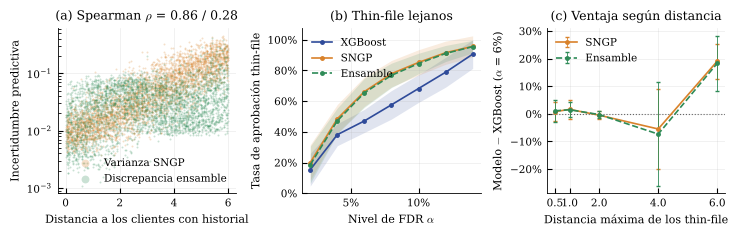

           SNGP        Ensamble       
           mean    std     mean    std
dist_max                              
0.5       0.008  0.034    0.011  0.039
1.0       0.016  0.034    0.015  0.027
2.0      -0.005  0.015   -0.003  0.012
4.0      -0.055  0.143   -0.073  0.188
6.0       0.191  0.063    0.183  0.099


In [4]:
# Bloque 4. Figura 5 del informe (archivo F4_simulacion), en tres paneles:
# (a) incertidumbre contra distancia para los thin-file de una semilla (varianza de la SNGP sola y discrepancia del
#     ensamble): muestra que el mecanismo existe (más lejos, más incertidumbre);
# (b) aprobación thin-file contra alfa en el escenario lejano (dist_max = 6): cuando los thin-file están lejos, esa
#     incertidumbre se traduce en más aprobados con la misma garantía;
# (c) ventaja de la SNGP y del ensamble (puntos de aprobación sobre XGBoost, alfa 6%) según qué tan lejos están los
#     thin-file. Es el panel que conecta con Home Credit: la ventaja aparece solo cuando están lejos, y en Home Credit
#     la varianza de los thin-file es apenas 12% mayor que la del resto (estamos del lado izquierdo del panel).
from estilo import *                                   # paleta azul-violeta y estilo común (ver estilo.py)

fig, ejes = plt.subplots(1, 3, figsize=(7.6, 2.6))

# (a) varianza vs distancia: puntos tenues (una muestra) y, encima, la mediana de cada medida por tramo de distancia
d = pool_ejemplo[pool_ejemplo["thin"]].reset_index(drop=True)
mu_sub = d.sample(1500, random_state=0)                    # muestra de puntos, para que se vea la nube sin tapar las líneas
tramos = np.linspace(0, 6, 9)                              # 8 tramos de distancia
centros = (tramos[:-1] + tramos[1:]) / 2
for col, nombre, color, marca in [("var_sngp", "Varianza SNGP", COLORES["SNGP"], "o"),
                                  ("disc_ens", "Discrepancia ensamble", COLORES["GP"], "s")]:
    ejes[0].scatter(mu_sub["dist"], mu_sub[col], s=1.5, alpha=0.18, color=color, linewidths=0)
    med = [d.loc[(d["dist"] >= a_) & (d["dist"] < b_), col].median() for a_, b_ in zip(tramos[:-1], tramos[1:])]
    ejes[0].plot(centros, med, "-", marker=marca, color=color, linewidth=1.6, markersize=3.5, label=nombre)   # mediana por tramo
ejes[0].set_yscale("log")                                  # la incertidumbre crece por órdenes de magnitud
ejes[0].set_xlabel("Distancia a los clientes con historial")
ejes[0].set_ylabel("Incertidumbre predictiva")
rho_v = spearmanr(d["dist"], d["var_sngp"])[0]
rho_d = spearmanr(d["dist"], d["disc_ens"])[0]
ejes[0].legend(frameon=False, loc="upper left")
ejes[0].set_title(rf"(a) Spearman $\rho$ = {rho_v:.2f} / {rho_d:.2f}")

# (b) aprobación vs alfa, escenario lejano
for modelo in ["XGBoost", "SNGP", "Ensamble"]:
    q = res[(res.dist_max == 6.0) & (res.version == "por segmento") & (res.modelo == modelo)]
    ejes[1].plot(q["alfa"], q["tasa"], ESTILOS[modelo], color=COLORES[modelo], linewidth=2.0 if modelo == "XGBoost" else 1.2,
                 marker=MARCAS[modelo], markersize=3.8, markerfacecolor=COLORES[modelo] if RELLENO[modelo] else "white",
                 markeredgecolor=COLORES[modelo], markeredgewidth=0.9, label=modelo)
    ejes[1].fill_between(q["alfa"], q["tasa"] - q["tasa_sd"], q["tasa"] + q["tasa_sd"],
                         color=COLORES[modelo], alpha=0.08, linewidth=0)
ejes[1].set_xlabel(r"Nivel de FDR $\alpha$")
ejes[1].set_ylabel("Tasa de aprobación thin-file")
ejes[1].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ejes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ejes[1].legend(frameon=False, loc="upper left")
ejes[1].set_title("(b) Thin-file lejanos")

# (c) ventaja según distancia: diferencia por semilla, media +/- 1 desvío
q = sim[(sim.version == "por segmento") & (sim.alfa == 0.06)]
tasas = q.pivot_table(index=["dist_max", "semilla"], columns="modelo", values="tasa")
dif = {}
for modelo in ["SNGP", "Ensamble"]:
    dif[modelo] = (tasas[modelo] - tasas["XGBoost"]).groupby("dist_max").agg(["mean", "std"])
    xs = np.arange(len(dif[modelo])) + (0.09 if modelo == "Ensamble" else -0.09)   # posición por escenario, con un corrimiento chico para que no se tapen
    ejes[2].errorbar(xs, dif[modelo]["mean"], yerr=dif[modelo]["std"], fmt=ESTILOS[modelo],
                     color=COLORES[modelo], linewidth=1.3, marker=MARCAS[modelo], markersize=4,
                     markerfacecolor=COLORES[modelo] if RELLENO[modelo] else "white", markeredgecolor=COLORES[modelo],
                     capsize=2, elinewidth=0.8, label=modelo)
ejes[2].legend(frameon=False, loc="upper left")
ejes[2].set_xticks(range(len(ESCENARIOS)), ["0,5", "1", "2", "4", "6"])
ejes[2].axhline(0, color="0.4", linewidth=0.8, linestyle=":")
ejes[2].set_xlabel(r"Distancia máxima de los thin-file")
ejes[2].set_ylabel(r"Modelo $-$ XGBoost ($\alpha$ = 6%)")
ejes[2].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ejes[2].set_title("(c) Ventaja según distancia")

fig.tight_layout()
fig.savefig("outputs/F4_simulacion.pdf", bbox_inches="tight")
fig.savefig("outputs/F4_simulacion.png", dpi=300, bbox_inches="tight")
plt.show()
print(pd.concat(dif, axis=1).round(3))

# Ventaja sobre XGBoost a alfa 6% (media y desvío entre semillas), SNGP / ensamble:
#   distancia 0.5: +0.8 / +1.1 puntos | 1: +1.6 / +1.5 | 2: -0.5 / -0.3 | 4: -5.5 (±14) / -7.3 (±19) | 6: +19.1 (±6) / +18.3 (±10).
# O sea que hasta distancia 2 la ventaja está entre -0,5 y +1,6 puntos (prácticamente cero), a distancia 4 el
# resultado es tan ruidoso que no se distingue de cero, y recién a distancia 6 la ventaja es clara y mucho mayor que
# el ruido. Es casi la misma para la SNGP y el ensamble: cuando los thin-file están lejos, el ensamble no agrega nada
# sobre una SNGP sola, y es más ruidoso entre semillas.
# El título del panel (a) da rho = 0.86 para la varianza y 0.28 para la discrepancia (en esa semilla).

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


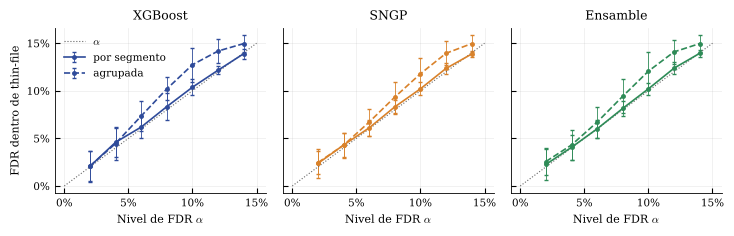

In [5]:
# Bloque 5. Figura 6 del informe (archivo F5_fdr_thin_sim): FDR real dentro de thin-file contra alfa en el escenario
# lejano, calibrando por segmento y agrupado, para los tres modelos. Es el mismo resultado que en Home Credit pero con
# la verdad conocida: calibrar con todos juntos hace que, dentro del segmento minoritario, la proporción de morosos
# supere lo prometido.
fig, ejes = plt.subplots(1, 3, figsize=(7.4, 2.4), sharey=True)
for ax, modelo in zip(ejes, ["XGBoost", "SNGP", "Ensamble"]):
    for version, estilo in [("por segmento", "-"), ("agrupada", "--")]:
        q = res[(res.dist_max == 6.0) & (res.version == version) & (res.modelo == modelo)]
        ax.errorbar(q["alfa"], q["fdr"], yerr=q["fdr_sd"], fmt=estilo, color=COLORES[modelo],
                    linewidth=1.2, marker=MARCAS[modelo], markersize=2.5, capsize=1.5, elinewidth=0.6,
                    label=version)
    ax.plot([0, 0.15], [0, 0.15], color="0.4", linewidth=0.8, linestyle=":", label=r"$\alpha$")
    ax.set_title(modelo)
    ax.set_xlabel(r"Nivel de FDR $\alpha$")
    ax.set_xticks([0, 0.05, 0.10, 0.15])                       # marcas en 0%, 5%, 10%, 15%
    ax.set_yticks([0, 0.05, 0.10, 0.15])
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ejes[0].set_ylabel("FDR dentro de thin-file")
ejes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("outputs/F5_fdr_thin_sim.pdf", bbox_inches="tight")
fig.savefig("outputs/F5_fdr_thin_sim.png", dpi=300, bbox_inches="tight")
plt.show()

# Igual que en Home Credit: por segmento la FDR queda pegada a la diagonal (se pasa como mucho 0.006, ruido de 10
# semillas) y la agrupada se pasa bastante dentro de thin-file. Con alfa 10%: 12,7% en XGBoost, 11,8% en la SNGP y
# 12,1% en el ensamble, contra 10,4%, 10,2% y 10,2% por segmento.

In [6]:
# Bloque 6. ¿Cómo ordena cada modelo a los thin-file lejanos? (el mecanismo de la sección 4.3)
# Tomamos la semilla del panel (a) (distancia máxima 6, semilla 0) y cortamos a los thin-file del pool en tramos de
# distancia. Para cada tramo comparamos la mora real con el riesgo que predice cada modelo. Después, dentro de los
# lejanos (distancia > 4, bien adentro de la trampa), medimos si el modelo los ordena bien (AUC) y si su riesgo
# predicho sube con la distancia (Spearman). Por último, a cuántos aprueba cada uno con Conformal Selection por
# segmento a alfa 6% (calibrando con una mitad del pool, como en el Bloque 3).
from scipy.stats import rankdata

d = pool_ejemplo[pool_ejemplo["thin"]].reset_index(drop=True)
TRAMOS = [(0, 1), (1, 2.5), (2.5, 4), (4, 5), (5, 6)]   # tramos de distancia; la trampa empieza en 2.5
en_tramo = [((d["dist"] > a) | (a == 0)) & (d["dist"] <= b) for a, b in TRAMOS]
print("tramo de distancia:      ", "  ".join(f"{a}-{b}" for a, b in TRAMOS))
print("mora real:               ", "  ".join(f"{d['y'][m].mean():.3f}" for m in en_tramo))
for modelo, col in MODELOS.items():
    riesgo = 1 - d[col]   # riesgo predicho = 1 - prob. de buen pago
    print(f"riesgo predicho {modelo:9s}", "  ".join(f"{riesgo[m].mean():.3f}" for m in en_tramo))

lejos = (d["dist"] > 4).to_numpy()
y_e, thin_e = pool_ejemplo["y"].to_numpy(), pool_ejemplo["thin"].to_numpy()
i_cal, i_test = train_test_split(np.arange(len(pool_ejemplo)), test_size=0.5, stratify=2 * thin_e + y_e, random_state=0)
c, t = i_cal[thin_e[i_cal]], i_test[thin_e[i_test]]
lejos_t = pool_ejemplo["dist"].to_numpy()[t] > 4
print()
for modelo, col in MODELOS.items():
    riesgo = 1 - d[col].to_numpy()
    mu = pool_ejemplo[col].to_numpy()
    a = conformal_select(mu[c], y_e[c], mu[t], 0.06, np.random.default_rng(0))
    print(f"{modelo:9s} dentro de los lejanos: AUC {roc_auc_score(d['y'][lejos], riesgo[lejos]):.3f}, Spearman riesgo-distancia "
          f"{spearmanr(d['dist'][lejos], riesgo[lejos])[0]:.2f} | conformal alfa 6%: aprueba {a.mean():.0%} con "
          f"{y_e[t][a].mean():.1%} de morosos (lejanos {a[lejos_t].mean():.0%}, cercanos {a[~lejos_t].mean():.0%})")

# Acá se ve el mecanismo con la verdad conocida. La mora real sube fuerte dentro de la trampa (6,5% entre 2,5 y 4,
# 21,7% entre 4 y 5, 39,7% entre 5 y 6). XGBoost se queda con lo último que aprendió en el borde de los datos y les da
# a todos los lejanos casi el mismo riesgo (~7-8%): no distingue a uno a distancia 3 de uno a distancia 6 (dentro de
# los lejanos su AUC es 0,555, casi azar, y su riesgo no sube con la distancia, Spearman 0,05). La SNGP también
# subestima la mora de los lejanos, pero su predicción vuelve hacia el promedio a medida que se aleja de los datos:
# su riesgo predicho sube con la distancia (de 4,1% a 7,8%) y los ordena bien entre sí (AUC 0,782, Spearman 0,43).
# Como Conformal Selection solo usa el orden, eso alcanza: XGBoost, que mezcla a los de la trampa con los demás,
# tiene que ser más estricto con todos para cumplir alfa y aprueba al 38%, mientras que la SNGP aprueba al 62%
# (y el ensamble al 57%). Es una sola partición de una semilla, así que la FDR de cada uno puede pasarse un poco de
# alfa (la garantía es en promedio, como se ve en la Figura 6); el resultado promedio es el de los Bloques 3 y 4.

tramo de distancia:       0-1  1-2.5  2.5-4  4-5  5-6
mora real:                0.100  0.052  0.065  0.217  0.397
riesgo predicho XGBoost   0.105  0.065  0.067  0.077  0.079
riesgo predicho SNGP      0.095  0.051  0.041  0.054  0.078
riesgo predicho Ensamble  0.105  0.064  0.051  0.056  0.066

XGBoost   dentro de los lejanos: AUC 0.555, Spearman riesgo-distancia 0.05 | conformal alfa 6%: aprueba 38% con 7.4% de morosos (lejanos 24%, cercanos 46%)
SNGP      dentro de los lejanos: AUC 0.782, Spearman riesgo-distancia 0.43 | conformal alfa 6%: aprueba 62% con 6.2% de morosos (lejanos 46%, cercanos 70%)
Ensamble  dentro de los lejanos: AUC 0.786, Spearman riesgo-distancia 0.46 | conformal alfa 6%: aprueba 57% con 5.7% de morosos (lejanos 46%, cercanos 62%)
